## 1. Setup

In [ ]:
# Colab already ships torch / transformers / scikit-learn / pandas. We only add what's missing and
# deliberately DO NOT pin or downgrade transformers (the old notebook broke on that).
!pip install -q faiss-cpu sentence-transformers spacy sentencepiece protobuf
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 62.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 57.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, json, random, time, warnings, subprocess, sys, importlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, requests
import matplotlib.pyplot as plt
import faiss, spacy
import transformers, sklearn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "/content" if os.path.isdir("/content") else "."
print("device:", DEVICE)
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| sklearn", sklearn.__version__, "| faiss", faiss.__version__, "| spacy", spacy.__version__)

# ---- Experiment configuration (edit here if you want a bigger / smaller run) ----
GEN_QUERIES = ["Albert Einstein", "Who invented the telephone", "Marie Curie", "Great Wall of China",
               "Isaac Newton", "Mount Everest", "Theory of relativity", "Amazon River",
               "Leonardo da Vinci", "World War II", "Apollo 11", "Mahatma Gandhi"]
EVAL_TOPICS = ["Albert Einstein", "Marie Curie", "Isaac Newton", "Leonardo da Vinci", "Alexander Graham Bell",
               "Mount Everest", "Amazon River", "Great Wall of China", "Eiffel Tower", "Taj Mahal",
               "World War II", "French Revolution", "Apollo 11", "Theory of relativity", "Photosynthesis",
               "DNA", "Roman Empire", "Industrial Revolution", "Nelson Mandela", "Mahatma Gandhi"]
SENTS_PER_TOPIC = 10     # lead-section sentences tried per topic

device: cpu
torch 2.11.0+cpu | transformers 5.18.0 | sklearn 1.6.1 | faiss 1.15.1 | spacy 3.8.16


## 2. Load models

In [ ]:
from sentence_transformers import SentenceTransformer
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForQuestionAnswering,
                          AutoModelForSequenceClassification)
import torch.nn.functional as F

embedder = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
    importlib.invalidate_caches()
    nlp = spacy.load("en_core_web_sm")

# Two different generative models for consensus checking
tokenizer_1 = AutoTokenizer.from_pretrained("google/flan-t5-large")
model_1 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-large").to(DEVICE).eval()
tokenizer_2 = AutoTokenizer.from_pretrained("google/flan-t5-base")
model_2 = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(DEVICE).eval()

def generate_text(prompt, tokenizer, model, max_new_tokens=150):
    instruction = f"Answer the following question with several factual sentences: {prompt}"
    inputs = tokenizer(instruction, return_tensors="pt", truncation=True).to(DEVICE)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4, do_sample=False)
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Extractive QA (SQuAD2). Implemented directly instead of via pipeline("question-answering"),
# which was removed in transformers v5 -- this works on every version.
QA_NAME = "deepset/roberta-base-squad2"
qa_tokenizer = AutoTokenizer.from_pretrained(QA_NAME)
qa_model = AutoModelForQuestionAnswering.from_pretrained(QA_NAME).to(DEVICE).eval()

def extractive_qa(question, context, max_len=384, stride=128, max_answer_len=30, batch_size=8):
    enc = qa_tokenizer(question, context, truncation="only_second", max_length=max_len, stride=stride,
                       return_overflowing_tokens=True, return_offsets_mapping=True,
                       padding="max_length", return_tensors="pt")
    n = enc["input_ids"].shape[0]
    best, best_logit, null_logit = {"answer": "", "score": 0.0}, -1e9, 1e9
    for b in range(0, n, batch_size):
        ids = enc["input_ids"][b:b+batch_size].to(DEVICE)
        am = enc["attention_mask"][b:b+batch_size].to(DEVICE)
        with torch.no_grad():
            out = qa_model(input_ids=ids, attention_mask=am)
        sl, el = out.start_logits.cpu(), out.end_logits.cpu()
        for j in range(sl.shape[0]):
            i = b + j
            seq = enc.sequence_ids(i)
            offs = enc["offset_mapping"][i].tolist()
            s, e = sl[j], el[j]
            null_logit = min(null_logit, float(s[0] + e[0]))
            ps, pe = torch.softmax(s, 0), torch.softmax(e, 0)
            ctx_idx = [t for t, sid in enumerate(seq) if sid == 1]
            top_s = sorted(ctx_idx, key=lambda t: -float(s[t]))[:20]
            top_e = sorted(ctx_idx, key=lambda t: -float(e[t]))[:20]
            for a in top_s:
                for c in top_e:
                    if c < a or c - a + 1 > max_answer_len:
                        continue
                    sc = float(s[a] + e[c])
                    if sc > best_logit:
                        best_logit = sc
                        best = {"answer": context[offs[a][0]:offs[c][1]], "score": float(ps[a] * pe[c])}
    if null_logit > best_logit:
        return {"answer": "(no answer found in context)", "score": 0.0}
    return best

# NLI verifier. Label order is read from the model config, never hard-coded.
NLI_MODEL_NAME = "cross-encoder/nli-deberta-v3-small"
nli_tokenizer = AutoTokenizer.from_pretrained(NLI_MODEL_NAME)
nli_model = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL_NAME).to(DEVICE).eval()
NLI_ID2LABEL = {int(k): v.lower() for k, v in nli_model.config.id2label.items()}
print("NLI label mapping:", NLI_ID2LABEL)
print("All models loaded successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (42 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

NLI label mapping: {0: 'contradiction', 1: 'entailment', 2: 'neutral'}
All models loaded successfully.


## 3. Wikipedia retrieval, FAISS index & sentence risk scoring

In [ ]:
WIKI_API_URL = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "HallucinationDetectionPipeline/1.0 (educational research project)"}
_WIKI_CACHE = {}

def _wiki_search_title(query):
    params = {"action": "query", "list": "search", "srsearch": query, "format": "json", "srlimit": 5}
    resp = requests.get(WIKI_API_URL, params=params, headers=WIKI_HEADERS, timeout=15)
    resp.raise_for_status()
    results = resp.json().get("query", {}).get("search", [])
    return results[0]["title"] if results else None

def _wiki_get_page_text(title):
    params = {"action": "query", "prop": "extracts", "explaintext": 1, "titles": title,
              "format": "json", "redirects": 1}
    resp = requests.get(WIKI_API_URL, params=params, headers=WIKI_HEADERS, timeout=15)
    resp.raise_for_status()
    for page_id, page in resp.json().get("query", {}).get("pages", {}).items():
        return "" if page_id == "-1" else page.get("extract", "")
    return ""

def fetch_wikipedia_content(query, max_chars=20000):
    key = (query, max_chars)
    if key in _WIKI_CACHE:
        return _WIKI_CACHE[key]
    content = ""
    for attempt in range(3):
        try:
            title = _wiki_search_title(query)
            if not title:
                print(f"No Wikipedia results for '{query}'."); break
            content = _wiki_get_page_text(title)[:max_chars]
            break
        except Exception as e:
            print(f"[retry {attempt+1}] Wikipedia fetch error for '{query}':", e); time.sleep(2)
    _WIKI_CACHE[key] = content
    return content

def chunk_content(content):
    doc = nlp(content)
    return [s.text.strip() for s in doc.sents if len(s.text.strip()) > 20]

def build_faiss_index(content):
    chunks = chunk_content(content)
    if not chunks:
        raise ValueError("No usable chunks were extracted from the retrieved content.")
    emb = embedder.encode(chunks, normalize_embeddings=True)
    index = faiss.IndexFlatIP(emb.shape[1])
    index.add(np.array(emb, dtype="float32"))
    return index, chunks

def baseline_label(sim):
    """Retrieval-only baseline thresholds (unchanged from the original design)."""
    return "Low Risk" if sim > 0.65 else ("Medium Risk" if sim > 0.45 else "High Risk")

def retrieve(sentence, index, chunks, exclude_idx=None, k=3):
    """Top-1 evidence chunk; optionally skips one chunk (used to hold the source sentence out)."""
    qv = embedder.encode([sentence], normalize_embeddings=True)
    D, I = index.search(np.array(qv, dtype="float32"), k=min(k, len(chunks)))
    for d, i in zip(D[0], I[0]):
        if i == -1 or (exclude_idx is not None and int(i) == exclude_idx):
            continue
        return float(d), int(i), chunks[int(i)]
    return 0.0, -1, ""

def verify_sentence(sentence, index, chunks):
    sim, _, matched = retrieve(sentence, index, chunks)
    return baseline_label(sim), sim, matched

def correct_output(sentences, index, chunks, mode="correction"):
    """mode='correction' replaces High-Risk sentences with retrieved evidence;
    mode='transparency' flags them but keeps them visible."""
    corrected, log = [], []
    for s in sentences:
        risk_label, sim, matched = verify_sentence(s, index, chunks)
        log.append({"sentence": s, "risk": risk_label, "similarity": round(sim, 3), "matched": matched})
        if risk_label == "High Risk":
            corrected.append(matched.strip() if mode == "correction" else f"[UNVERIFIED: {s}]")
        else:
            corrected.append(s)
    return " ".join(corrected), log
print("Retrieval + baseline + correction ready.")

Retrieval + baseline + correction ready.


## 4. Core pipeline (generation → consensus → grounded QA → sentence risk → correction)

In [ ]:
def hallucination_pipeline(user_query, mode="correction", consensus_threshold=0.80, verbose=True):
    context = fetch_wikipedia_content(user_query)
    if not context:
        print("No grounding context could be retrieved for:", user_query); return None
    try:
        index, chunks = build_faiss_index(context)
    except ValueError as e:
        print(e); return None

    out1 = generate_text(user_query, tokenizer_1, model_1)
    out2 = generate_text(user_query, tokenizer_2, model_2)
    emb1, emb2 = embedder.encode([out1, out2], normalize_embeddings=True)
    consensus_score = float(np.dot(emb1, emb2))
    consensus = consensus_score >= consensus_threshold

    try:
        qa_result = extractive_qa(user_query, context)
    except Exception as e:
        print("QA model failed:", e); qa_result = {"answer": "N/A", "score": 0.0}

    sentences = [s.text.strip() for s in nlp(out1).sents if s.text.strip()]
    if not sentences:
        print("Model 1 produced no usable sentences:", user_query); return None
    corrected_answer, risk_log = correct_output(sentences, index, chunks, mode=mode)

    risk_counts = {"Low Risk": 0, "Medium Risk": 0, "High Risk": 0}
    for e in risk_log: risk_counts[e["risk"]] += 1
    total = len(risk_log) or 1
    if risk_counts["High Risk"] / total > 0.4:
        overall = "HIGH overall hallucination risk"
    elif (risk_counts["Medium Risk"] + risk_counts["High Risk"]) > total / 2:
        overall = "MEDIUM overall hallucination risk"
    else:
        overall = "LOW overall hallucination risk"

    if verbose:
        print("--- Raw Generation (Model 1: flan-t5-large) ---\n", out1)
        print("\n--- Raw Generation (Model 2: flan-t5-base) ---\n", out2)
        print(f"\n--- Consensus similarity = {consensus_score:.2f} ->", "AGREE" if consensus else "DISAGREE")
        print("\n--- Extractive QA answer ---\n", qa_result["answer"], f"(conf={qa_result['score']:.2f})")
        print("\n--- Sentence risk map (FAISS baseline) ---")
        for e in risk_log:
            print(f"[{e['risk']:11s}] (sim={e['similarity']}) {e['sentence']}")
        print(f"\n--- Overall verdict: {overall} ---")
        print("\n--- Corrected output ---\n", corrected_answer)

    return {"raw_output_1": out1, "raw_output_2": out2, "consensus": consensus,
            "consensus_score": consensus_score, "qa_answer": qa_result["answer"], "qa_conf": qa_result["score"],
            "risk_log": risk_log, "overall_verdict": overall, "corrected_output": corrected_answer}
print("Pipeline ready.")

Pipeline ready.


## 5. Multi-signal verification: NLI, generation confidence, atomic facts, taxonomy, ensemble

In [ ]:
def compute_nli_probs(evidence, claim):
    if not evidence:
        return {"entailment": 0.0, "neutral": 1.0, "contradiction": 0.0}
    inputs = nli_tokenizer(evidence, claim, return_tensors="pt", truncation=True).to(DEVICE)
    with torch.no_grad():
        logits = nli_model(**inputs).logits
    probs = F.softmax(logits, dim=-1)[0].tolist()
    return {NLI_ID2LABEL[i]: probs[i] for i in range(len(probs))}

def compute_generation_confidence(user_query, generated_text, tokenizer, model):
    """exp(-NLL) of the model's own output under teacher forcing (geometric-mean token probability)."""
    instruction = f"Answer the following question with several factual sentences: {user_query}"
    inputs = tokenizer(instruction, return_tensors="pt", truncation=True).to(model.device)
    labels = tokenizer(generated_text, return_tensors="pt", truncation=True).input_ids.to(model.device)
    with torch.no_grad():
        out = model(**inputs, labels=labels)
    return float(np.exp(-out.loss.item()))

ATOMIC_LABELS = {"DATE", "TIME", "CARDINAL", "QUANTITY", "MONEY", "PERCENT",
                 "PERSON", "GPE", "ORG", "NORP", "LOC", "FAC", "EVENT"}

def extract_atomic_facts(sentence):
    return [(e.text, e.label_) for e in nlp(sentence).ents if e.label_ in ATOMIC_LABELS]

def verify_atomic_facts(sentence, evidence):
    facts = extract_atomic_facts(sentence)
    if not facts:
        return None, []
    ev = evidence.lower()
    mismatches = [(t, l) for t, l in facts if t.lower() not in ev]
    return 1 - len(mismatches) / len(facts), mismatches

def classify_hallucination_type(nli_probs, atomic_mismatches):
    if nli_probs.get("contradiction", 0.0) > 0.5:
        return "Direct Contradiction"
    if atomic_mismatches:
        labels = {l for _, l in atomic_mismatches}
        if labels & {"DATE", "TIME"}: return "Temporal Error"
        if labels & {"CARDINAL", "QUANTITY", "MONEY", "PERCENT"}: return "Numeric Error"
        if labels & {"PERSON", "ORG", "GPE", "NORP", "LOC", "FAC", "EVENT"}: return "Entity Substitution"
    if nli_probs.get("entailment", 0.0) < 0.3 and nli_probs.get("contradiction", 0.0) < 0.3:
        return "Unsupported / Fabricated Claim"
    return "Consistent"

def ensemble_verdict(retrieval_similarity, nli_probs, atomic_match_rate,
                     w_retrieval=0.4, w_nli=0.4, w_atomic=0.2):
    nli_signal = nli_probs.get("entailment", 0.0) - nli_probs.get("contradiction", 0.0)
    score = w_retrieval * retrieval_similarity + w_nli * nli_signal
    score += w_atomic * (atomic_match_rate if atomic_match_rate is not None else retrieval_similarity)
    score = max(0.0, min(1.0, score))
    if nli_probs.get("contradiction", 0.0) > 0.5: label = "High Risk"
    elif score > 0.6: label = "Low Risk"
    elif score > 0.35: label = "Medium Risk"
    else: label = "High Risk"
    return round(score, 3), label
print("Multi-signal components ready.")

Multi-signal components ready.


In [ ]:
session_log = []

def run_multi_signal_analysis(user_query, pipeline_result, mode="correction", verbose=True):
    confidence = compute_generation_confidence(user_query, pipeline_result["raw_output_1"], tokenizer_1, model_1)
    enriched = []
    ens_counts = {"Low Risk": 0, "Medium Risk": 0, "High Risk": 0}
    after_counts = dict(ens_counts)
    taxonomy_counts = {}
    for entry in pipeline_result["risk_log"]:
        sentence, evidence = entry["sentence"], entry["matched"]
        nli_probs = compute_nli_probs(evidence, sentence)
        rate, mism = verify_atomic_facts(sentence, evidence)
        score, label = ensemble_verdict(entry["similarity"], nli_probs, rate)
        h_type = "Consistent" if label == "Low Risk" else classify_hallucination_type(nli_probs, mism)
        ens_counts[label] += 1
        taxonomy_counts[h_type] = taxonomy_counts.get(h_type, 0) + 1
        # After correction, every FAISS-High sentence is replaced by retrieved evidence (grounded by
        # construction). NOTE: this is a mechanism check, not an independent accuracy measure.
        after_label = "Low Risk" if (mode == "correction" and entry["risk"] == "High Risk") else label
        after_counts[after_label] += 1
        enriched.append({**entry, "ensemble_score": score, "ensemble_label": label,
                         "nli_entailment": round(nli_probs.get("entailment", 0.0), 3),
                         "nli_contradiction": round(nli_probs.get("contradiction", 0.0), 3),
                         "atomic_match_rate": rate, "hallucination_type": h_type, "after_label": after_label})
    total = len(enriched) or 1
    record = {
        "query": user_query, "mode": mode, "n_sentences": total,
        "faiss_risk_counts": {k: sum(1 for e in pipeline_result["risk_log"] if e["risk"] == k)
                              for k in ["Low Risk", "Medium Risk", "High Risk"]},
        "ensemble_risk_counts": ens_counts, "after_risk_counts": after_counts,
        "taxonomy_counts": taxonomy_counts, "generation_confidence": round(confidence, 4),
        "consensus": pipeline_result["consensus"], "consensus_score": round(pipeline_result["consensus_score"], 3),
        "qa_answer": pipeline_result["qa_answer"], "qa_conf": round(pipeline_result["qa_conf"], 3),
        "raw_output_1": pipeline_result["raw_output_1"], "raw_output_2": pipeline_result["raw_output_2"],
        "corrected_output": pipeline_result["corrected_output"], "details": enriched}
    session_log.append(record)
    if verbose:
        print(f"--- Multi-signal analysis: '{user_query}' ---")
        print("FAISS-only risk counts:  ", record["faiss_risk_counts"])
        print("Ensemble risk counts:    ", record["ensemble_risk_counts"])
        print("After-correction counts: ", record["after_risk_counts"])
        print("Hallucination taxonomy:  ", record["taxonomy_counts"])
        print(f"Generation confidence:    {record['generation_confidence']}\n")
        for e in enriched:
            print(f"[{e['ensemble_label']:11s} | {e['hallucination_type']:28s} | score={e['ensemble_score']}] {e['sentence']}")
    return record
print("Session tracking ready.")

Session tracking ready.


## 6. Demo — one query end to end (verbose)

In [ ]:
demo_query = "Albert Einstein"
demo_result = hallucination_pipeline(demo_query, mode="correction", verbose=True)
if demo_result:
    print("\n" + "=" * 90)
    run_multi_signal_analysis(demo_query, demo_result, mode="correction", verbose=True)

--- Raw Generation (Model 1: flan-t5-large) ---
 Einstein was a physicist

--- Raw Generation (Model 2: flan-t5-base) ---
 Albert Einstein was a physicist and physicist.

--- Consensus similarity = 0.93 -> AGREE

--- Extractive QA answer ---
 (no answer found in context) (conf=0.00)

--- Sentence risk map (FAISS baseline) ---
[Low Risk   ] (sim=0.768) Einstein was a physicist

--- Overall verdict: LOW overall hallucination risk ---

--- Corrected output ---
 Einstein was a physicist

--- Multi-signal analysis: 'Albert Einstein' ---
FAISS-only risk counts:   {'Low Risk': 1, 'Medium Risk': 0, 'High Risk': 0}
Ensemble risk counts:     {'Low Risk': 1, 'Medium Risk': 0, 'High Risk': 0}
After-correction counts:  {'Low Risk': 1, 'Medium Risk': 0, 'High Risk': 0}
Hallucination taxonomy:   {'Consistent': 1}
Generation confidence:    0.6123

[Low Risk    | Consistent                   | score=0.903] Einstein was a physicist


## 7. Experiment 1 — Generation analysis on real model outputs
Runs the full pipeline quietly on every query in `GEN_QUERIES` and fills `session_log`.

In [ ]:
t0 = time.time()
session_log.clear()
for q in GEN_QUERIES:
    r = hallucination_pipeline(q, mode="correction", verbose=False)
    if r is None:
        print("skipped:", q); continue
    run_multi_signal_analysis(q, r, mode="correction", verbose=False)
    print(f"done: {q:30s} ({len(session_log)}/{len(GEN_QUERIES)})")
print(f"Experiment 1 finished in {time.time()-t0:.0f}s, {len(session_log)} queries.")

done: Albert Einstein                (1/12)
done: Who invented the telephone     (2/12)
done: Marie Curie                    (3/12)
done: Great Wall of China            (4/12)
done: Isaac Newton                   (5/12)
done: Mount Everest                  (6/12)
done: Theory of relativity           (7/12)
done: Amazon River                   (8/12)
done: Leonardo da Vinci              (9/12)
done: World War II                   (10/12)
done: Apollo 11                      (11/12)
done: Mahatma Gandhi                 (12/12)
Experiment 1 finished in 258s, 12 queries.


In [ ]:
from IPython.display import display
rows = []
for r in session_log:
    rows.append({"query": r["query"], "n_sent": r["n_sentences"],
                 "FAISS high": r["faiss_risk_counts"]["High Risk"], "FAISS med": r["faiss_risk_counts"]["Medium Risk"],
                 "Ens high": r["ensemble_risk_counts"]["High Risk"], "Ens med": r["ensemble_risk_counts"]["Medium Risk"],
                 "gen_conf": r["generation_confidence"], "consensus": r["consensus_score"],
                 "agree": r["consensus"], "QA conf": r["qa_conf"]})
gen_df = pd.DataFrame(rows)
display(gen_df)

tot = gen_df["n_sent"].sum()
gen_stats = {
    "n_queries": int(len(gen_df)), "n_sentences": int(tot),
    "faiss_high_pct": round(100 * gen_df["FAISS high"].sum() / tot, 1),
    "faiss_flagged_pct": round(100 * (gen_df["FAISS high"].sum() + gen_df["FAISS med"].sum()) / tot, 1),
    "ensemble_high_pct": round(100 * gen_df["Ens high"].sum() / tot, 1),
    "ensemble_flagged_pct": round(100 * (gen_df["Ens high"].sum() + gen_df["Ens med"].sum()) / tot, 1),
    "mean_gen_conf": round(float(gen_df["gen_conf"].mean()), 3), "std_gen_conf": round(float(gen_df["gen_conf"].std()), 3),
    "mean_consensus": round(float(gen_df["consensus"].mean()), 3),
    "consensus_agree_pct": round(100 * float(gen_df["agree"].mean()), 1),
}
tax_total = {}
for r in session_log:
    for k, v in r["taxonomy_counts"].items(): tax_total[k] = tax_total.get(k, 0) + v
gen_stats["taxonomy_counts"] = tax_total
print(json.dumps(gen_stats, indent=2))

# Does generation confidence track hallucination rate?
from scipy.stats import spearmanr
frac_high = (gen_df["Ens high"] / gen_df["n_sent"]).values
if len(gen_df) > 3 and np.std(frac_high) > 0:
    rho, p = spearmanr(gen_df["gen_conf"], frac_high)
    gen_stats["spearman_conf_vs_high_frac"] = {"rho": round(float(rho), 3), "p": round(float(p), 3)}
    print(f"Spearman(generation confidence, fraction High-Risk) = {rho:.3f} (p={p:.3f}, n={len(gen_df)})")

,query,n_sent,FAISS high,FAISS med,Ens high,Ens med,gen_conf,consensus,agree,QA conf
0,Albert Einstein,1,0,0,0,0,0.6123,0.930,True,0.000
1,Who invented the telephone,1,0,0,1,0,0.5065,0.558,False,0.099
2,Marie Curie,1,0,0,0,0,0.4871,0.721,False,0.000
3,Great Wall of China,1,0,0,0,1,0.6568,0.652,False,0.000
4,Isaac Newton,1,0,0,0,0,0.6364,0.762,False,0.000
5,Mount Everest,1,0,0,0,0,0.6624,0.982,True,0.000
6,Theory of relativity,1,0,1,0,1,0.5727,0.548,False,0.000
7,Amazon River,1,0,0,0,0,0.6126,0.856,True,0.000
8,Leonardo da Vinci,1,0,0,0,0,0.7199,1.000,True,0.000
9,World War II,1,0,0,0,0,0.5348,0.708,False,0.000


{
  "n_queries": 12,
  "n_sentences": 12,
  "faiss_high_pct": 0.0,
  "faiss_flagged_pct": 8.3,
  "ensemble_high_pct": 8.3,
  "ensemble_flagged_pct": 33.3,
  "mean_gen_conf": 0.6,
  "std_gen_conf": 0.069,
  "mean_consensus": 0.756,
  "consensus_agree_pct": 33.3,
  "taxonomy_counts": {
    "Consistent": 8,
    "Entity Substitution": 1,
    "Unsupported / Fabricated Claim": 3
  }
}
Spearman(generation confidence, fraction High-Risk) = -0.393 (p=0.206, n=12)


## 8. Research dashboard (all queries)

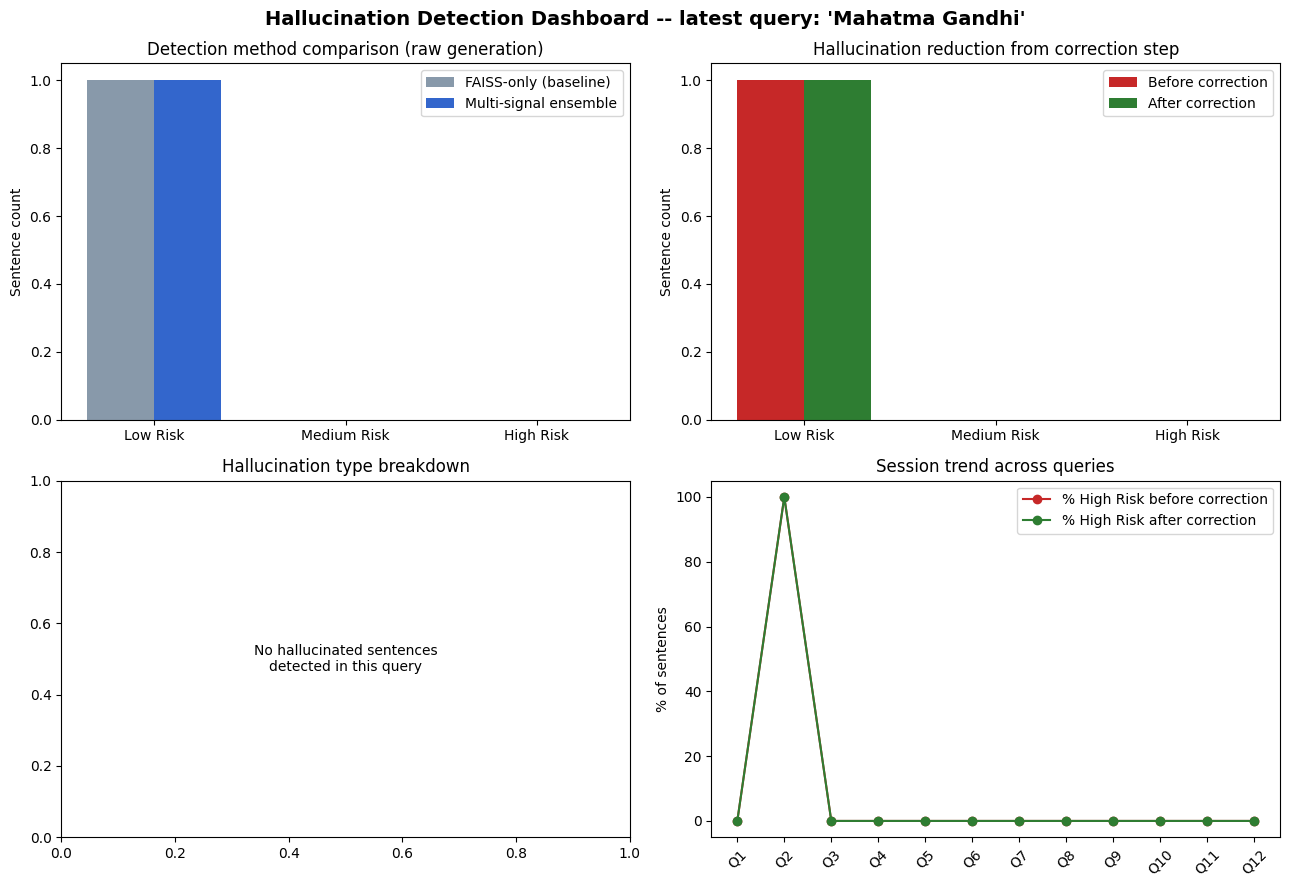

Queries analyzed:              12
Total sentences checked:       12
High-risk before correction:   1
High-risk after correction:    1
Hallucination reduction:       0.0%
Average generation confidence:  0.600


,sentence,risk,ensemble_label,hallucination_type,similarity,nli_entailment,nli_contradiction,atomic_match_rate
0,Mahatma Gandhi was an Indian nationalist,Low Risk,Low Risk,Consistent,0.712,0.982,0.001,0.5


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RISK_LABELS = ["Low Risk", "Medium Risk", "High Risk"]
RISK_COLORS = {"Low Risk": "#2e7d32", "Medium Risk": "#ef6c00", "High Risk": "#c62828"}

def render_dashboard(session_log):
    if not session_log:
        print("No analysis runs yet -- call run_multi_signal_analysis(...) at least once first.")
        return

    latest = session_log[-1]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(f"Hallucination Detection Dashboard -- latest query: '{latest['query']}'",
                 fontsize=14, fontweight="bold")

    ax = axes[0, 0]
    x = np.arange(len(RISK_LABELS))
    width = 0.35
    faiss_vals = [latest["faiss_risk_counts"][l] for l in RISK_LABELS]
    ens_vals = [latest["ensemble_risk_counts"][l] for l in RISK_LABELS]
    ax.bar(x - width/2, faiss_vals, width, label="FAISS-only (baseline)", color="#8899aa")
    ax.bar(x + width/2, ens_vals, width, label="Multi-signal ensemble", color="#3366cc")
    ax.set_xticks(x); ax.set_xticklabels(RISK_LABELS)
    ax.set_ylabel("Sentence count")
    ax.set_title("Detection method comparison (raw generation)")
    ax.legend()

    ax = axes[0, 1]
    before_vals = [latest["ensemble_risk_counts"][l] for l in RISK_LABELS]
    after_vals = [latest["after_risk_counts"][l] for l in RISK_LABELS]
    ax.bar(x - width/2, before_vals, width, label="Before correction", color="#c62828")
    ax.bar(x + width/2, after_vals, width, label="After correction", color="#2e7d32")
    ax.set_xticks(x); ax.set_xticklabels(RISK_LABELS)
    ax.set_ylabel("Sentence count")
    ax.set_title("Hallucination reduction from correction step")
    ax.legend()

    ax = axes[1, 0]
    tax = {k: v for k, v in latest["taxonomy_counts"].items() if k != "Consistent"}
    if tax:
        ax.pie(tax.values(), labels=tax.keys(), autopct="%1.0f%%", startangle=90,
               colors=plt.cm.Set2.colors)
    else:
        ax.text(0.5, 0.5, "No hallucinated sentences\ndetected in this query",
                 ha="center", va="center")
    ax.set_title("Hallucination type breakdown")

    ax = axes[1, 1]
    q_labels = [f"Q{i+1}" for i in range(len(session_log))]
    before_pct = [100 * r["ensemble_risk_counts"]["High Risk"] / max(r["n_sentences"], 1) for r in session_log]
    after_pct = [100 * r["after_risk_counts"]["High Risk"] / max(r["n_sentences"], 1) for r in session_log]
    ax.plot(q_labels, before_pct, marker="o", label="% High Risk before correction", color="#c62828")
    ax.plot(q_labels, after_pct, marker="o", label="% High Risk after correction", color="#2e7d32")
    ax.set_ylabel("% of sentences")
    ax.set_title("Session trend across queries")
    ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=45)

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/dashboard_last.png", dpi=150)
    plt.show()

    total_sentences = sum(r["n_sentences"] for r in session_log)
    total_before_high = sum(r["ensemble_risk_counts"]["High Risk"] for r in session_log)
    total_after_high = sum(r["after_risk_counts"]["High Risk"] for r in session_log)
    avg_conf = float(np.mean([r["generation_confidence"] for r in session_log]))
    reduction_pct = (100 * (total_before_high - total_after_high) / total_before_high
                      if total_before_high > 0 else None)

    print(f"Queries analyzed:              {len(session_log)}")
    print(f"Total sentences checked:       {total_sentences}")
    print(f"High-risk before correction:   {total_before_high}")
    print(f"High-risk after correction:    {total_after_high}")
    if reduction_pct is not None:
        print(f"Hallucination reduction:       {reduction_pct:.1f}%")
    print(f"Average generation confidence:  {avg_conf:.3f}")

    df = pd.DataFrame(latest["details"])[
        ["sentence", "risk", "ensemble_label", "hallucination_type",
         "similarity", "nli_entailment", "nli_contradiction", "atomic_match_rate"]
    ]
    display(df)

render_dashboard(session_log)

## 9. Experiment 2 — Controlled benchmark with automatic ground truth
For each topic, take lead-section sentences from Wikipedia (**factual**), and create a counterpart with **one injected error** — a changed year (*Temporal*), changed number (*Numeric*) or swapped named entity (*Entity*). Ground truth is therefore exact: original = `factual`, perturbed = `hallucinated`.

> **Reading the two settings:** in Setting A the original (factual) sentence is verbatim in the index, so the *factual* side is easy and false-positive rates are optimistic; the informative question there is whether a subtle error is caught when the truth is retrievable. Setting B is the conservative test and should be the headline number for generalisation.

In [ ]:
rng = random.Random(SEED)

YEAR_RE = re.compile(r"\b(1[0-9]{3}|20[0-9]{2})\b")
NUM_RE = re.compile(r"\d[\d,]*\.?\d*")
ENT_LABELS = ("PERSON", "GPE", "ORG", "NORP", "LOC", "FAC", "EVENT")

def make_entity_pool(text):
    pool = {}
    for ent in nlp(text).ents:
        if ent.label_ in ENT_LABELS:
            pool.setdefault(ent.label_, set()).add(ent.text.strip())
    return {k: sorted(v) for k, v in pool.items()}

def perturb(sentence, pool, rng):
    """Inject exactly one error. Returns (new_sentence, type, original_span, new_span) or None."""
    cands = []
    for ent in nlp(sentence).ents:
        if ent.label_ == "DATE" and YEAR_RE.search(ent.text):
            cands.append(("Temporal Error", ent))
        elif ent.label_ in ("CARDINAL", "QUANTITY", "MONEY", "PERCENT") and re.search(r"\d", ent.text):
            cands.append(("Numeric Error", ent))
        elif ent.label_ in ENT_LABELS:
            cands.append(("Entity Substitution", ent))
    rng.shuffle(cands)
    for ptype, ent in cands:
        new = None
        if ptype == "Temporal Error":
            m = YEAR_RE.search(ent.text); y = int(m.group())
            new = ent.text.replace(m.group(), str(max(1, y + rng.choice([-1, 1]) * rng.randint(3, 40))), 1)
        elif ptype == "Numeric Error":
            m = NUM_RE.search(ent.text); raw = m.group()
            try:
                val = float(raw.replace(",", "")) * rng.choice([2, 3, 0.5])
                rep = str(int(round(val))) if "." not in raw else f"{val:.1f}"
                if rep != raw.replace(",", ""):
                    new = ent.text.replace(raw, rep, 1)
            except ValueError:
                new = None
        else:
            options = [t for t in pool.get(ent.label_, [])
                       if t.lower() != ent.text.lower() and t.lower() not in sentence.lower()]
            if options:
                new = rng.choice(options)
        if new and new != ent.text:
            return sentence[:ent.start_char] + new + sentence[ent.end_char:], ptype, ent.text, new
    return None

topic_data, items = {}, []
for t_id, topic in enumerate(EVAL_TOPICS):
    ctx = fetch_wikipedia_content(topic)
    if not ctx:
        print("skipping topic (no content):", topic); continue
    index, chunks = build_faiss_index(ctx)
    pool = make_entity_pool(ctx)
    topic_data[topic] = (index, chunks)
    made = 0
    for ci, ch in enumerate(chunks[:40]):
        if made >= SENTS_PER_TOPIC: break
        if not (40 <= len(ch) <= 300) or "\n" in ch or "==" in ch: continue
        p = perturb(ch, pool, rng)
        if p is None: continue
        new_sent, ptype, orig_span, new_span = p
        base = {"topic": topic, "topic_id": t_id, "src_idx": ci, "source_sentence": ch}
        items.append({**base, "sentence": ch, "true_label": "factual", "perturbation": "none",
                      "orig_span": "", "new_span": ""})
        items.append({**base, "sentence": new_sent, "true_label": "hallucinated", "perturbation": ptype,
                      "orig_span": orig_span, "new_span": new_span})
        made += 1

items_df = pd.DataFrame(items)
print(f"Benchmark built: {len(items_df)} sentences from {items_df.topic.nunique()} topics "
      f"({(items_df.true_label=='hallucinated').sum()} hallucinated / {(items_df.true_label=='factual').sum()} factual)")
print("\nInjected error types:"); print(items_df[items_df.true_label == "hallucinated"].perturbation.value_counts().to_string())
print("\nExamples (original -> perturbed):")
ex = items_df[items_df.true_label == "hallucinated"].head(5)
for _, r in ex.iterrows():
    print(f" [{r.perturbation}] {r.orig_span!r} -> {r.new_span!r}\n   {r.sentence}")

[retry 1] Wikipedia fetch error for 'Nelson Mandela': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&list=search&srsearch=Nelson+Mandela&format=json&srlimit=5
[retry 2] Wikipedia fetch error for 'Nelson Mandela': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&list=search&srsearch=Nelson+Mandela&format=json&srlimit=5
[retry 3] Wikipedia fetch error for 'Nelson Mandela': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&list=search&srsearch=Nelson+Mandela&format=json&srlimit=5
skipping topic (no content): Nelson Mandela
Benchmark built: 374 sentences from 19 topics (187 hallucinated / 187 factual)

Injected error types:
perturbation
Entity Substitution    152
Temporal Error          20
Numeric Error           15

Examples (original -> perturbed):
 [Temporal Error] '18 April 1955' -> '18 April 1938'
   Albert Einstein (14 March 1879 – 18 April 1938) was a 

### 9.1 Score every benchmark sentence (both settings)

In [ ]:
def score_item(sentence, index, chunks, exclude_idx=None):
    sim, mi, matched = retrieve(sentence, index, chunks, exclude_idx)
    nli = compute_nli_probs(matched, sentence)
    rate, mism = verify_atomic_facts(sentence, matched)
    ens_score, ens_label = ensemble_verdict(sim, nli, rate)
    return {"sim": sim, "matched": matched, "matched_idx": mi,
            "nli_ent": nli.get("entailment", 0.0), "nli_con": nli.get("contradiction", 0.0),
            "atomic_rate": rate, "n_mismatch": len(mism),
            "ens_score": ens_score, "ens_label": ens_label, "base_label": baseline_label(sim),
            "pred_type": classify_hallucination_type(nli, mism)}

def score_all(items_df, hold_out):
    recs = []
    for _, r in items_df.iterrows():
        index, chunks = topic_data[r.topic]
        s = score_item(r.sentence, index, chunks, exclude_idx=r.src_idx if hold_out else None)
        recs.append({**r.to_dict(), **s})
    return pd.DataFrame(recs)

t0 = time.time()
df_A = score_all(items_df, hold_out=False)   # Setting A: evidence present
df_B = score_all(items_df, hold_out=True)    # Setting B: evidence held out
print(f"Scored {len(df_A)} sentences x 2 settings in {time.time()-t0:.0f}s")

Scored 374 sentences x 2 settings in 249s


### 9.2 Detection metrics: retrieval-only baseline vs. multi-signal ensemble


===== Setting A: evidence present | n=374 (187 hallucinated) =====

(a) Hallucination-class metrics at the pipeline's built-in thresholds


,method (default thresholds),precision,recall,F1,accuracy
0,FAISS-only: High Risk,0.0,0.000,0.000,0.500
1,FAISS-only: Medium+High,1.0,0.016,0.032,0.508
2,Ensemble: High Risk,1.0,0.717,0.835,0.858
3,Ensemble: Medium+High,1.0,0.898,0.946,0.949


(b) Threshold-free AUROC (ablation of individual signals)


,signal,AUROC
0,FAISS similarity only (baseline),1.000
1,NLI only,0.984
2,Atomic-fact only,0.971
3,Ensemble (all signals),0.999


(c) Calibrated on 180 items / evaluated on 194 held-out-topic items


,signal,threshold(tuned on cal. topics),precision,recall,F1
0,FAISS similarity only (baseline),0.000,1.000,1.000,1.000
1,NLI only,-0.855,0.978,0.928,0.952
2,Atomic-fact only,0.091,1.000,0.959,0.979
3,Ensemble (all signals),0.062,0.990,0.979,0.984


(d) Delta F1 (Ensemble-High minus FAISS-High) = +0.833, 95% bootstrap CI [+0.790, +0.874]
(e) Recall by injected error type


,error type,n,FAISS-only recall,Ensemble recall
0,Entity Substitution,152,0.0,0.658
1,Numeric Error,15,0.0,1.000
2,Temporal Error,20,0.0,0.950


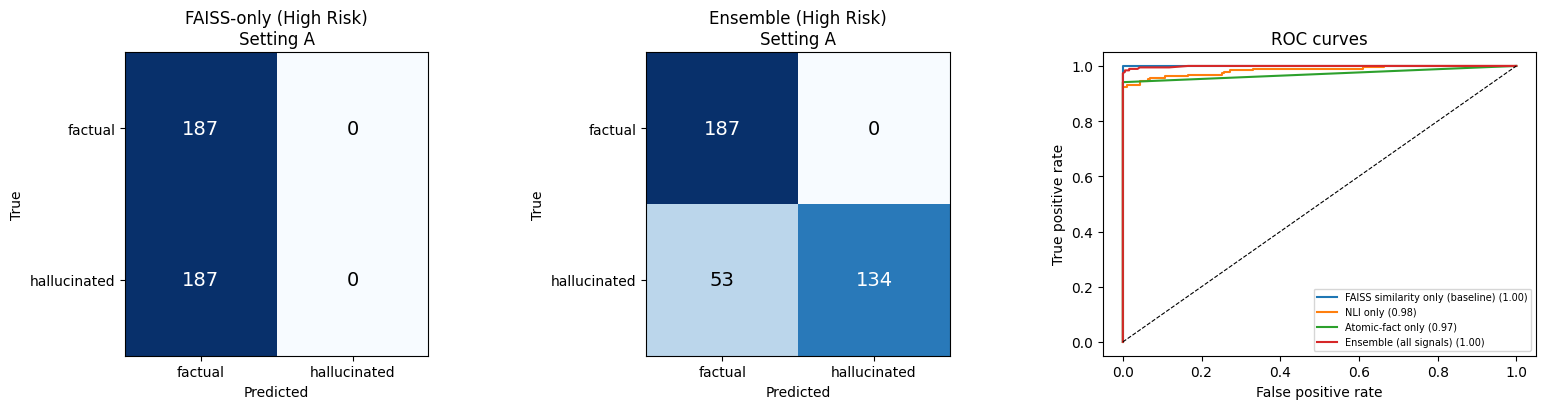

In [ ]:
from sklearn.metrics import (precision_recall_fscore_support, f1_score, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)

def prf(y, pred):
    P, R, F1, _ = precision_recall_fscore_support(y, pred, average="binary", pos_label=1, zero_division=0)
    return P, R, F1

def hall_scores(df):
    """Continuous hallucination scores (higher = more likely hallucinated) for each signal."""
    return {
        "FAISS similarity only (baseline)": (1 - df.sim).values,
        "NLI only": (-(df.nli_ent - df.nli_con)).values,
        "Atomic-fact only": (1 - df.atomic_rate.fillna(0.5)).values,
        "Ensemble (all signals)": (1 - df.ens_score).values,
    }

def best_threshold(y, s):
    P, R, T = precision_recall_curve(y, s)
    if len(T) == 0: return 0.5
    f = 2 * P[:-1] * R[:-1] / np.maximum(P[:-1] + R[:-1], 1e-9)
    return float(T[int(np.argmax(f))])

def boot_delta_f1(y, pa, pb, n=1000, seed=0):
    r = np.random.default_rng(seed); idx = np.arange(len(y)); d = []
    for _ in range(n):
        s = r.choice(idx, len(idx), replace=True)
        d.append(f1_score(y[s], pb[s], zero_division=0) - f1_score(y[s], pa[s], zero_division=0))
    return float(np.mean(d)), [float(x) for x in np.percentile(d, [2.5, 97.5])]

def evaluate_setting(df, name):
    y = (df.true_label == "hallucinated").astype(int).values
    res = {"setting": name, "n": int(len(df)), "n_hallucinated": int(y.sum())}

    # (a) as-designed thresholds
    preds = {
        "FAISS-only: High Risk": (df.base_label == "High Risk").astype(int).values,
        "FAISS-only: Medium+High": (df.base_label != "Low Risk").astype(int).values,
        "Ensemble: High Risk": (df.ens_label == "High Risk").astype(int).values,
        "Ensemble: Medium+High": (df.ens_label != "Low Risk").astype(int).values,
    }
    rows = []
    for k, p in preds.items():
        P, R, F1 = prf(y, p)
        rows.append({"method (default thresholds)": k, "precision": round(P, 3), "recall": round(R, 3), "F1": round(F1, 3),
                     "accuracy": round(float((p == y).mean()), 3)})
    t1 = pd.DataFrame(rows); res["default_thresholds"] = rows
    print(f"\n===== {name} | n={len(df)} ({y.sum()} hallucinated) =====")
    print("\n(a) Hallucination-class metrics at the pipeline's built-in thresholds"); display(t1)

    # (b) threshold-free ranking quality + ablation
    sc = hall_scores(df); rows = []
    for k, s in sc.items():
        rows.append({"signal": k, "AUROC": round(roc_auc_score(y, s), 3)})
    t2 = pd.DataFrame(rows); res["auroc"] = rows
    print("(b) Threshold-free AUROC (ablation of individual signals)"); display(t2)

    # (c) topic-split calibration: tune on even topics, report on odd topics
    cal = (df.topic_id % 2 == 0).values; te = ~cal
    rows = []
    for k, s in sc.items():
        thr = best_threshold(y[cal], s[cal]); p = (s[te] >= thr).astype(int)
        P, R, F1 = prf(y[te], p)
        rows.append({"signal": k, "threshold(tuned on cal. topics)": round(thr, 3),
                     "precision": round(P, 3), "recall": round(R, 3), "F1": round(F1, 3)})
    t3 = pd.DataFrame(rows); res["calibrated_heldout"] = rows
    print(f"(c) Calibrated on {cal.sum()} items / evaluated on {te.sum()} held-out-topic items"); display(t3)

    # (d) paired bootstrap, ensemble(High) vs baseline(High)
    m, ci = boot_delta_f1(y, preds["FAISS-only: High Risk"], preds["Ensemble: High Risk"])
    res["delta_f1_ens_vs_base_high"] = {"mean": round(m, 3), "ci95": [round(c, 3) for c in ci]}
    print(f"(d) Delta F1 (Ensemble-High minus FAISS-High) = {m:+.3f}, 95% bootstrap CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")

    # per-error-type recall
    h = df[df.true_label == "hallucinated"]
    rows = []
    for ptype, g in h.groupby("perturbation"):
        rows.append({"error type": ptype, "n": len(g),
                     "FAISS-only recall": round(float((g.base_label == "High Risk").mean()), 3),
                     "Ensemble recall": round(float((g.ens_label == "High Risk").mean()), 3)})
    t4 = pd.DataFrame(rows); res["recall_by_type"] = rows
    print("(e) Recall by injected error type"); display(t4)

    # figures
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for ax, (nm, p) in zip(axes[:2], [("FAISS-only (High Risk)", preds["FAISS-only: High Risk"]),
                                       ("Ensemble (High Risk)", preds["Ensemble: High Risk"])]):
        cm = confusion_matrix(y, p, labels=[0, 1])
        ax.imshow(cm, cmap="Blues"); ax.set_title(f"{nm}\n{name.split(':')[0]}")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["factual", "hallucinated"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["factual", "hallucinated"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        res.setdefault("confusion_matrices", {})[nm] = cm.tolist()
    for k, s in sc.items():
        fpr, tpr, _ = roc_curve(y, s); axes[2].plot(fpr, tpr, label=f"{k} ({roc_auc_score(y, s):.2f})")
    axes[2].plot([0, 1], [0, 1], "k--", lw=0.8); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
    axes[2].set_title("ROC curves"); axes[2].legend(fontsize=7)
    plt.tight_layout()
    fn = f"{OUT_DIR}/fig_eval_{name.split(':')[0].replace(' ', '_')}.png"
    plt.savefig(fn, dpi=150); plt.show()
    return res

resA = evaluate_setting(df_A, "Setting A: evidence present")


===== Setting B: evidence held out | n=374 (187 hallucinated) =====

(a) Hallucination-class metrics at the pipeline's built-in thresholds


,method (default thresholds),precision,recall,F1,accuracy
0,FAISS-only: High Risk,0.688,0.059,0.108,0.516
1,FAISS-only: Medium+High,0.561,0.636,0.596,0.570
2,Ensemble: High Risk,0.556,0.856,0.674,0.586
3,Ensemble: Medium+High,0.514,0.995,0.678,0.527


(b) Threshold-free AUROC (ablation of individual signals)


,signal,AUROC
0,FAISS similarity only (baseline),0.604
1,NLI only,0.605
2,Atomic-fact only,0.591
3,Ensemble (all signals),0.627


(c) Calibrated on 180 items / evaluated on 194 held-out-topic items


,signal,threshold(tuned on cal. topics),precision,recall,F1
0,FAISS similarity only (baseline),0.269,0.520,0.918,0.664
1,NLI only,-0.004,0.512,0.907,0.654
2,Atomic-fact only,0.333,0.529,0.948,0.679
3,Ensemble (all signals),0.612,0.530,0.907,0.669


(d) Delta F1 (Ensemble-High minus FAISS-High) = +0.565, 95% bootstrap CI [+0.488, +0.637]
(e) Recall by injected error type


,error type,n,FAISS-only recall,Ensemble recall
0,Entity Substitution,152,0.046,0.829
1,Numeric Error,15,0.067,1.000
2,Temporal Error,20,0.150,0.950


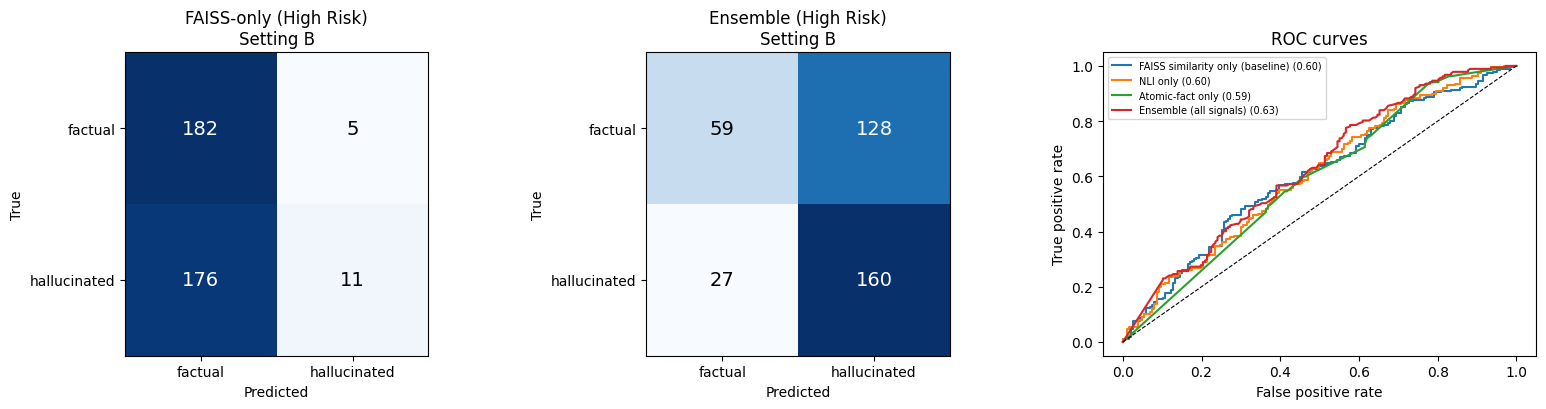

In [ ]:
resB = evaluate_setting(df_B, "Setting B: evidence held out")

### 9.3 Hallucination taxonomy accuracy (does the typed classifier name the injected error?)


Setting A: evidence present: confusion between injected error type (rows) and predicted type (columns)


pred_type,Consistent,Direct Contradiction,Entity Substitution,Numeric Error,Unsupported / Fabricated Claim
perturbation,,,,,
Entity Substitution,5,97,48,0,2
Numeric Error,0,15,0,0,0
Temporal Error,0,19,0,1,0


Exact-type accuracy by injected type:
perturbation
Entity Substitution    0.316
Numeric Error          0.000
Temporal Error         0.000
Overall exact-type accuracy: 0.257   |   labelled 'Consistent' (missed): 0.027


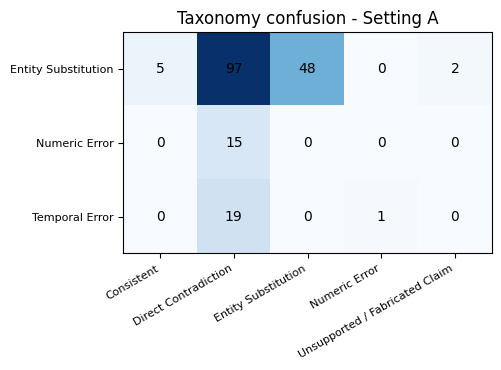


Setting B: evidence held out: confusion between injected error type (rows) and predicted type (columns)


pred_type,Consistent,Direct Contradiction,Entity Substitution,Numeric Error,Temporal Error,Unsupported / Fabricated Claim
perturbation,,,,,,
Entity Substitution,1,38,46,13,45,9
Numeric Error,0,6,0,8,1,0
Temporal Error,0,6,0,0,14,0


Exact-type accuracy by injected type:
perturbation
Entity Substitution    0.303
Numeric Error          0.533
Temporal Error         0.700
Overall exact-type accuracy: 0.364   |   labelled 'Consistent' (missed): 0.005


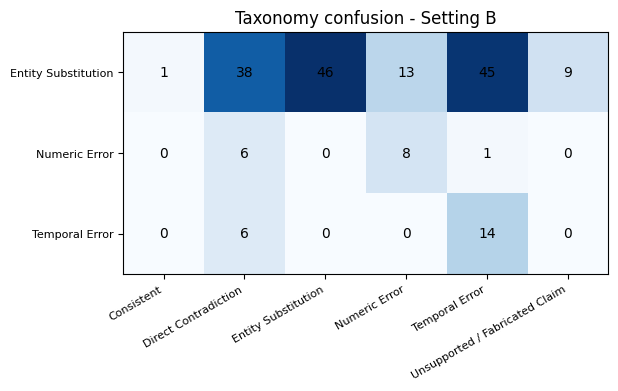

In [ ]:
def taxonomy_eval(df, name):
    h = df[df.true_label == "hallucinated"]
    ct = pd.crosstab(h.perturbation, h.pred_type)
    print(f"\n{name}: confusion between injected error type (rows) and predicted type (columns)")
    display(ct)
    acc_by = h.assign(ok=(h.perturbation == h.pred_type)).groupby("perturbation").ok.mean().round(3)
    overall = float((h.perturbation == h.pred_type).mean())
    print("Exact-type accuracy by injected type:"); print(acc_by.to_string())
    print(f"Overall exact-type accuracy: {overall:.3f}   |   labelled 'Consistent' (missed): {(h.pred_type=='Consistent').mean():.3f}")
    fig, ax = plt.subplots(figsize=(7, 3.8)); im = ax.imshow(ct.values, cmap="Blues")
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index, fontsize=8)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha="center", va="center")
    ax.set_title(f"Taxonomy confusion - {name.split(':')[0]}"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig_taxonomy_{name.split(':')[0].replace(' ', '_')}.png", dpi=150); plt.show()
    return {"overall_accuracy": round(overall, 3), "by_type": acc_by.to_dict(), "crosstab": ct.to_dict()}

tax_A = taxonomy_eval(df_A, "Setting A: evidence present")
tax_B = taxonomy_eval(df_B, "Setting B: evidence held out")

## 10. Correction analysis
Two views: (i) the real generations from Experiment 1, and (ii) a *measurable* correction test on the benchmark: when a hallucinated sentence is flagged, does replacing it with the top retrieved sentence restore the true fact (Setting A, where the truth is in the index)?

In [ ]:
# (i) Real generations: what does correction actually replace?
repl = []
for r in session_log:
    for d in r["details"]:
        if d["risk"] == "High Risk":
            repl.append({"query": r["query"], "original": d["sentence"], "replacement": d["matched"],
                         "sim(original, replacement)": d["similarity"], "ensemble_label": d["ensemble_label"],
                         "type": d["hallucination_type"]})
repl_df = pd.DataFrame(repl)
n_total = sum(r["n_sentences"] for r in session_log)
corr_stats = {"n_sentences": n_total, "n_replaced": int(len(repl_df)),
              "pct_replaced": round(100 * len(repl_df) / max(n_total, 1), 1)}
if len(repl_df):
    corr_stats["mean_sim_original_vs_replacement"] = round(float(repl_df["sim(original, replacement)"].mean()), 3)
    print(f"{len(repl_df)}/{n_total} generated sentences were replaced ({corr_stats['pct_replaced']}%).")
    print("Mean similarity between a replaced sentence and its replacement:", corr_stats["mean_sim_original_vs_replacement"],
          "(by definition <= 0.45: replacements are only loosely related to the claim they replace)")
    print("\nBefore -> after examples:")
    with pd.option_context("display.max_colwidth", 200):
        display(repl_df.head(8))
else:
    print("No sentences crossed the High-Risk threshold in Experiment 1; nothing was replaced.")

No sentences crossed the High-Risk threshold in Experiment 1; nothing was replaced.


In [ ]:
# (ii) Measurable correction accuracy on the benchmark (Setting A)
h = df_A[df_A.true_label == "hallucinated"].copy()
h["fixed"] = (h.matched_idx == h.src_idx) | h.apply(lambda r: bool(r.orig_span) and r.orig_span.lower() in r.matched.lower(), axis=1)
rows = []
for trig, mask in [("FAISS-only trigger (original pipeline)", h.base_label == "High Risk"),
                   ("Ensemble trigger (proposed)", h.ens_label == "High Risk"),
                   ("Ensemble trigger, Medium+High", h.ens_label != "Low Risk")]:
    n_det = int(mask.sum()); n_fix = int((mask & h.fixed).sum())
    rows.append({"correction trigger": trig, "hallucinations": len(h), "detected": n_det,
                 "detection rate": round(n_det / len(h), 3),
                 "restored true fact | detected": round(n_fix / n_det, 3) if n_det else float("nan"),
                 "overall fixed rate": round(n_fix / len(h), 3)})
corr_tbl = pd.DataFrame(rows); display(corr_tbl)
corr_stats["benchmark_correction"] = rows
print("'overall fixed rate' = fraction of ALL injected errors that were both detected and replaced by the true sentence.")

,correction trigger,hallucinations,detected,detection rate,restored true fact | detected,overall fixed rate
0,FAISS-only trigger (original pipeline),187,0,0.000,NaN,0.000
1,Ensemble trigger (proposed),187,134,0.717,0.993,0.711
2,"Ensemble trigger, Medium+High",187,168,0.898,0.994,0.893


'overall fixed rate' = fraction of ALL injected errors that were both detected and replaced by the true sentence.


## 11. (Optional) Complement with hand-labelled real generations
Cell 1 exports the real generated sentences to `to_label.csv`. Fill the `true_label` column (`factual` / `hallucinated`) by checking each sentence against Wikipedia, upload it as `labeled_generations.csv` in the Colab file panel, then run Cell 2.

In [ ]:
rows = [{"query": r["query"], **{k: d[k] for k in ["sentence", "matched", "similarity", "risk", "ensemble_label",
         "ensemble_score", "hallucination_type"]}, "true_label": ""} for r in session_log for d in r["details"]]
pd.DataFrame(rows).to_csv(f"{OUT_DIR}/to_label.csv", index=False)
print(f"Exported {len(rows)} real generated sentences to {OUT_DIR}/to_label.csv")

Exported 12 real generated sentences to /content/to_label.csv


In [ ]:
lab_path = f"{OUT_DIR}/labeled_generations.csv"
real_eval = None
if os.path.exists(lab_path):
    L = pd.read_csv(lab_path); L = L[L.true_label.isin(["factual", "hallucinated"])]
    y = (L.true_label == "hallucinated").astype(int).values
    out = []
    for nm, p in [("FAISS-only: High Risk", (L.risk == "High Risk")), ("Ensemble: High Risk", (L.ensemble_label == "High Risk")),
                  ("Ensemble: Medium+High", (L.ensemble_label != "Low Risk"))]:
        P, R, F1 = prf(y, p.astype(int).values); out.append({"method": nm, "precision": round(P, 3), "recall": round(R, 3), "F1": round(F1, 3)})
    real_eval = {"n": int(len(L)), "n_hallucinated": int(y.sum()), "results": out}
    display(pd.DataFrame(out)); print(real_eval["n"], "labelled real sentences")
else:
    print("No labeled_generations.csv found -- skipping (this cell is optional).")

No labeled_generations.csv found -- skipping (this cell is optional).


## 12. Export everything (JSON, CSV, figures) and print the paper-ready summary

In [ ]:
import shutil
summary = {"config": {"gen_queries": GEN_QUERIES, "eval_topics": EVAL_TOPICS, "seed": SEED, "device": DEVICE,
                      "models": {"generator_large": "google/flan-t5-large", "generator_base": "google/flan-t5-base",
                                 "embedder": "all-MiniLM-L6-v2", "nli": NLI_MODEL_NAME, "qa": QA_NAME},
                      "ensemble_weights": {"retrieval": 0.4, "nli": 0.4, "atomic": 0.2},
                      "baseline_thresholds": {"low": 0.65, "medium": 0.45}},
           "generation_experiment": gen_stats, "benchmark_setting_A": resA, "benchmark_setting_B": resB,
           "taxonomy_A": tax_A, "taxonomy_B": tax_B, "correction": corr_stats, "real_labeled_eval": real_eval}
with open(f"{OUT_DIR}/results_summary.json", "w") as f: json.dump(summary, f, indent=2, default=str)
with open(f"{OUT_DIR}/session_log.json", "w") as f: json.dump(session_log, f, indent=2, default=str)

# eval_results.json in the format the Streamlit app expects (Setting A, ensemble High Risk)
yA = (df_A.true_label == "hallucinated").astype(int).values; pA = (df_A.ens_label == "High Risk").astype(int).values
P, R, F1 = prf(yA, pA)
with open(f"{OUT_DIR}/eval_results.json", "w") as f:
    json.dump({"y_true": ["hallucinated" if v else "factual" for v in yA], "y_pred": ["hallucinated" if v else "factual" for v in pA],
               "precision": P, "recall": R, "f1": F1, "confusion_matrix": confusion_matrix(yA, pA, labels=[0, 1]).tolist(),
               "labels": ["factual", "hallucinated"]}, f, indent=2)
df_A.to_csv(f"{OUT_DIR}/benchmark_scored_settingA.csv", index=False)
df_B.to_csv(f"{OUT_DIR}/benchmark_scored_settingB.csv", index=False)
gen_df.to_csv(f"{OUT_DIR}/generation_summary.csv", index=False)

print("=" * 80); print("PAPER-READY SUMMARY (copy these numbers into Results)"); print("=" * 80)
print(f"Experiment 1: {gen_stats['n_queries']} queries, {gen_stats['n_sentences']} generated sentences")
print(f"  FAISS-only High-Risk: {gen_stats['faiss_high_pct']}%  | Ensemble High-Risk: {gen_stats['ensemble_high_pct']}%")
print(f"  Mean generation confidence: {gen_stats['mean_gen_conf']} +/- {gen_stats['std_gen_conf']} | consensus agree: {gen_stats['consensus_agree_pct']}%")
for tag, res in [("A (evidence present)", resA), ("B (evidence held out)", resB)]:
    print(f"\nBenchmark setting {tag}: n={res['n']} ({res['n_hallucinated']} hallucinated)")
    for r in res["default_thresholds"]: print("  ", r)
    print("   AUROC:", {r["signal"]: r["AUROC"] for r in res["auroc"]})
    print("   dF1 ens-vs-base:", res["delta_f1_ens_vs_base_high"])
print("\nTaxonomy exact-type accuracy: A =", tax_A["overall_accuracy"], "| B =", tax_B["overall_accuracy"])
print("Correction:", json.dumps(corr_stats, indent=1, default=str))

res_dir = f"{OUT_DIR}/results_bundle"; os.makedirs(res_dir, exist_ok=True)
for fn in ["results_summary.json", "session_log.json", "eval_results.json", "benchmark_scored_settingA.csv",
           "benchmark_scored_settingB.csv", "generation_summary.csv", "to_label.csv", "dashboard_last.png"] +           [f for f in os.listdir(OUT_DIR) if f.startswith(("fig_eval_", "fig_taxonomy_"))]:
    if os.path.exists(f"{OUT_DIR}/{fn}"): shutil.copy(f"{OUT_DIR}/{fn}", res_dir)
try:
    zpath = shutil.make_archive(f"{OUT_DIR}/hallucination_results", "zip", res_dir)
    print("\nZipped outputs:", zpath)
    from google.colab import files; files.download(zpath)
except Exception as e:
    print("Download step skipped:", e)

PAPER-READY SUMMARY (copy these numbers into Results)
Experiment 1: 12 queries, 12 generated sentences
  FAISS-only High-Risk: 0.0%  | Ensemble High-Risk: 8.3%
  Mean generation confidence: 0.6 +/- 0.069 | consensus agree: 33.3%

Benchmark setting A (evidence present): n=374 (187 hallucinated)
   {'method (default thresholds)': 'FAISS-only: High Risk', 'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'accuracy': 0.5}
   {'method (default thresholds)': 'FAISS-only: Medium+High', 'precision': 1.0, 'recall': 0.016, 'F1': 0.032, 'accuracy': 0.508}
   {'method (default thresholds)': 'Ensemble: High Risk', 'precision': 1.0, 'recall': 0.717, 'F1': 0.835, 'accuracy': 0.858}
   {'method (default thresholds)': 'Ensemble: Medium+High', 'precision': 1.0, 'recall': 0.898, 'F1': 0.946, 'accuracy': 0.949}
   AUROC: {'FAISS similarity only (baseline)': np.float64(1.0), 'NLI only': np.float64(0.984), 'Atomic-fact only': np.float64(0.971), 'Ensemble (all signals)': np.float64(0.999)}
   dF1 ens-vs-base: {'me

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. (Optional) Streamlit dashboard

In [ ]:
%%writefile streamlit_app.py
"""
Hallucination Detection Research Dashboard
Run with:  streamlit run streamlit_app.py
"""

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Hallucination Detection Dashboard", layout="wide")

SESSION_LOG_PATH = "session_log.json"
EVAL_RESULTS_PATH = "eval_results.json"


@st.cache_data
def load_json(path):
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)


session_log = load_json(SESSION_LOG_PATH)
eval_results = load_json(EVAL_RESULTS_PATH)

st.title("LLM Hallucination Detection — Research Dashboard")

if not session_log:
    st.warning(
        f"No `{SESSION_LOG_PATH}` found next to this script. "
        "Run the evaluation cell in the notebook first (it exports this file)."
    )
    st.stop()

RISK_LABELS = ["Low Risk", "Medium Risk", "High Risk"]

query_options = [f"Q{i+1}: {r['query']}" for i, r in enumerate(session_log)]
selected_idx = st.sidebar.selectbox(
    "Select a query to inspect", range(len(session_log)),
    format_func=lambda i: query_options[i], index=len(session_log) - 1
)
selected = session_log[selected_idx]

st.sidebar.markdown("---")
st.sidebar.metric("Queries in session", len(session_log))
st.sidebar.metric("Sentences in selected query", selected["n_sentences"])
st.sidebar.metric("Generation confidence", f"{selected['generation_confidence']:.3f}")

total_sentences = sum(r["n_sentences"] for r in session_log)
total_before_high = sum(r["ensemble_risk_counts"]["High Risk"] for r in session_log)
total_after_high = sum(r["after_risk_counts"]["High Risk"] for r in session_log)
reduction_pct = (
    100 * (total_before_high - total_after_high) / total_before_high
    if total_before_high > 0 else None
)

c1, c2, c3, c4 = st.columns(4)
c1.metric("Total sentences checked", total_sentences)
c2.metric("High-risk before correction", total_before_high)
c3.metric("High-risk after correction", total_after_high)
c4.metric("Hallucination reduction", f"{reduction_pct:.1f}%" if reduction_pct is not None else "N/A")

st.markdown(f"### Selected query: `{selected['query']}`")

col1, col2 = st.columns(2)

with col1:
    st.subheader("Detection method comparison")
    fig, ax = plt.subplots(figsize=(5, 4))
    x = np.arange(len(RISK_LABELS))
    width = 0.35
    faiss_vals = [selected["faiss_risk_counts"][l] for l in RISK_LABELS]
    ens_vals = [selected["ensemble_risk_counts"][l] for l in RISK_LABELS]
    ax.bar(x - width / 2, faiss_vals, width, label="FAISS-only (baseline)", color="#8899aa")
    ax.bar(x + width / 2, ens_vals, width, label="Multi-signal ensemble", color="#3366cc")
    ax.set_xticks(x); ax.set_xticklabels(RISK_LABELS)
    ax.set_ylabel("Sentence count")
    ax.legend()
    st.pyplot(fig)

with col2:
    st.subheader("Before vs after correction")
    fig, ax = plt.subplots(figsize=(5, 4))
    before_vals = [selected["ensemble_risk_counts"][l] for l in RISK_LABELS]
    after_vals = [selected["after_risk_counts"][l] for l in RISK_LABELS]
    ax.bar(x - width / 2, before_vals, width, label="Before correction", color="#c62828")
    ax.bar(x + width / 2, after_vals, width, label="After correction", color="#2e7d32")
    ax.set_xticks(x); ax.set_xticklabels(RISK_LABELS)
    ax.set_ylabel("Sentence count")
    ax.legend()
    st.pyplot(fig)

col3, col4 = st.columns(2)

with col3:
    st.subheader("Hallucination type breakdown")
    tax = {k: v for k, v in selected["taxonomy_counts"].items() if k != "Consistent"}
    if tax:
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.pie(tax.values(), labels=tax.keys(), autopct="%1.0f%%", startangle=90,
               colors=plt.cm.Set2.colors)
        st.pyplot(fig)
    else:
        st.info("No hallucinated sentences detected in this query.")

with col4:
    st.subheader("Session trend across queries")
    fig, ax = plt.subplots(figsize=(5, 4))
    q_labels = [f"Q{i+1}" for i in range(len(session_log))]
    before_pct = [100 * r["ensemble_risk_counts"]["High Risk"] / max(r["n_sentences"], 1) for r in session_log]
    after_pct = [100 * r["after_risk_counts"]["High Risk"] / max(r["n_sentences"], 1) for r in session_log]
    ax.plot(q_labels, before_pct, marker="o", label="% High Risk before correction", color="#c62828")
    ax.plot(q_labels, after_pct, marker="o", label="% High Risk after correction", color="#2e7d32")
    ax.set_ylabel("% of sentences")
    ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=45)
    st.pyplot(fig)

st.subheader("Sentence-level detail (selected query)")
df = pd.DataFrame(selected["details"])[
    ["sentence", "risk", "ensemble_label", "hallucination_type",
     "similarity", "nli_entailment", "nli_contradiction", "atomic_match_rate"]
]
st.dataframe(df, use_container_width=True)

st.markdown("---")
st.header("Model Evaluation")

if not eval_results:
    st.info(
        f"No `{EVAL_RESULTS_PATH}` found. Fill in `eval_set` in the notebook's "
        "evaluation cell with real labeled examples to see P/R/F1 and a confusion matrix."
    )
else:
    m1, m2, m3 = st.columns(3)
    m1.metric("Precision (hallucinated)", f"{eval_results['precision']:.3f}")
    m2.metric("Recall (hallucinated)", f"{eval_results['recall']:.3f}")
    m3.metric("F1 (hallucinated)", f"{eval_results['f1']:.3f}")

    cm = np.array(eval_results["confusion_matrix"])
    labels = eval_results["labels"]

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title("Confusion Matrix — Ensemble Verifier")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    plt.colorbar(im)
    st.pyplot(fig)

Writing streamlit_app.py


In [ ]:
# Optional: launch the Streamlit dashboard (uncomment). Requires the JSON exports from section 12.
# !pip install -q streamlit
# !streamlit run streamlit_app.py --server.port 8501 &>/content/logs.txt &
# import time, urllib.request; time.sleep(5)
# print("Tunnel password (your Colab IP):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
# !npx -y localtunnel --port 8501